# Euro area and France: how good are the professional inflation forecasts?

**Objective:** evaluate the ECB Survey of Professional Forecasters (SPF): how big are the errors depending on the horizon, how much did they miss in 2021-2023, if the long-term expectations stayed anchored at 2%, and how is France compared to the euro area today.

**Data:**
- ECB SPF, HICP point forecasts of all the survey rounds since 1999 (ECB Data Portal)
- HICP of the euro area and France (ECB until December 2025, Eurostat ECOICOP v2 from 2026)
- ECB deposit facility rate

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests` and `statsmodels`.

## Part 1. Libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
ecb = lambda clave: pd.read_csv(f"https://data-api.ecb.europa.eu/service/data/{clave}?format=csvdata")

spf = ecb("SPF/Q.U2.HICP.POINT..Q.AVG")[["FCT_HORIZON", "TIME_PERIOD", "OBS_VALUE"]]
spf.columns = ["target", "survey", "forecast"]
spf.to_csv("data/spf_hicp.csv", index=False)

# monthly HICP y/y: ECB series until 2025 + Eurostat ECOICOP v2 from 2026 (the old series stopped)
h = ecb("ICP/M.U2+FR.N.000000.4.ANR").pivot_table(index="TIME_PERIOD", columns="REF_AREA", values="OBS_VALUE")
h.columns = ["France", "Euro area"] if list(h.columns) == ["FR", "U2"] else h.columns
js = requests.get("https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/prc_hicp_minr",
                  params=[("format", "JSON"), ("unit", "RCH_A"), ("coicop18", "TOTAL"), ("sinceTimePeriod", "2026-01"), ("geo", "EA"), ("geo", "FR")]).json()
geos, tiempos = js["dimension"]["geo"]["category"]["index"], js["dimension"]["time"]["category"]["index"]
nuevo = pd.DataFrame(index=sorted(tiempos, key=tiempos.get))
for g, gi in geos.items():
    nuevo["Euro area" if g == "EA" else "France"] = [js["value"].get(str(gi * len(tiempos) + ti)) for t, ti in sorted(tiempos.items(), key=lambda x: x[1])]
hicp = pd.concat([h.loc[:"2025-12"], nuevo])
hicp.index = pd.PeriodIndex(hicp.index, freq="M")
hicp.to_csv("data/hicp_yoy.csv")

# realised inflation of each calendar year = change of the annual average index
indice = ecb("ICP/M.U2.N.000000.4.INX")
indice = indice.set_index(pd.PeriodIndex(indice["TIME_PERIOD"], freq="M"))["OBS_VALUE"]
anual = indice.groupby(indice.index.year).mean()[indice.groupby(indice.index.year).size() == 12]
realizada = (anual.pct_change() * 100).dropna()

dfr = ecb("FM/D.U2.EUR.4F.KR.DFR.LEV")
dfr = dfr.set_index(pd.to_datetime(dfr["TIME_PERIOD"]))["OBS_VALUE"].resample("ME").last().ffill()
dfr.index = dfr.index.to_period("M")
print("Latest SPF round:", spf["survey"].max())
spf[spf["survey"] == spf["survey"].max()]

Latest SPF round: 2026-Q3


,target,survey,forecast
380,2026,2026-Q3,2.731677
391,2027,2026-Q3,2.173571
398,2028,2026-Q3,2.000777
407,2031,2026-Q3,2.036865
512,LT,2026-Q3,2.036865


## Part 2. Forecast errors by horizon

Each survey round gives forecasts for the current year and the next ones. We calculate the horizon in quarters from the survey to the end of the target year, and the error = forecast - realised.

In [3]:
s = spf[spf["target"].str.fullmatch(r"\d{4}")].copy()
s["target"] = s["target"].astype(int)
s["anio"] = s["survey"].str[:4].astype(int)
s["trim"] = s["survey"].str[-1].astype(int)
s["horizon_q"] = (s["target"] - s["anio"]) * 4 + (4 - s["trim"]) + 1
s = s.merge(realizada.rename("realised"), left_on="target", right_index=True)
s["error"] = s["forecast"] - s["realised"]

por_h = s.groupby("horizon_q")["error"].agg(n="size", bias="mean", rmse=lambda e: np.sqrt((e ** 2).mean()))
por_h["rmse_until_2019"] = s[s["target"] <= 2019].groupby("horizon_q")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
por_h.round(2).head(12)

,n,bias,rmse,rmse_until_2019
horizon_q,,,,
1,27,0.00,0.11,0.10
2,27,-0.05,0.28,0.15
3,27,-0.17,0.54,0.22
4,27,-0.31,1.17,0.45
5,26,-0.31,1.48,0.76
6,26,-0.38,1.62,0.84
7,26,-0.43,1.70,0.80
8,26,-0.45,1.76,0.81
9,24,-0.39,1.85,0.87


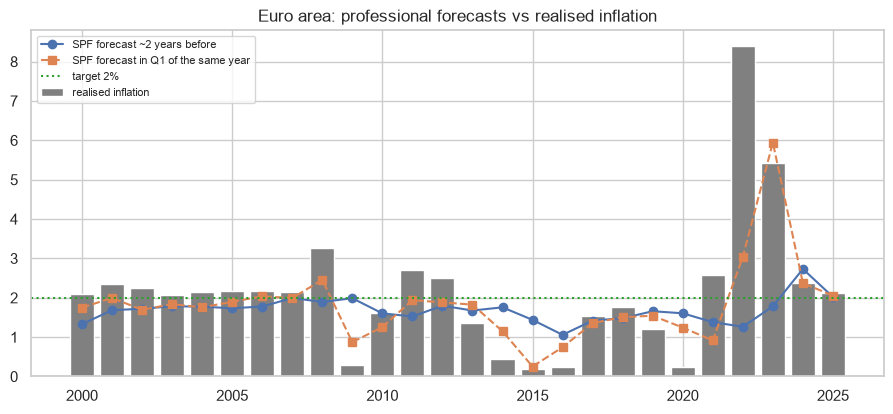

,target,survey,forecast,realised
310,2022,2021-Q1,1.26,8.38
309,2022,2020-Q4,1.26,8.38
308,2022,2020-Q3,1.28,8.38


In [4]:
anios = pd.DataFrame({"realised": realizada,
                      "forecast ~2 years before": s[s["horizon_q"] == 8].set_index("target")["forecast"],
                      "forecast in Q1 of the year": s[s["horizon_q"] == 4].set_index("target")["forecast"]}).loc[2000:]
plt.figure(figsize=(11, 4.5))
plt.bar(anios.index, anios["realised"], color="grey", label="realised inflation")
plt.plot(anios.index, anios["forecast ~2 years before"], marker="o", label="SPF forecast ~2 years before")
plt.plot(anios.index, anios["forecast in Q1 of the year"], marker="s", ls="--", label="SPF forecast in Q1 of the same year")
plt.axhline(2, color="tab:green", ls=":", label="target 2%")
plt.title("Euro area: professional forecasts vs realised inflation")
plt.legend(fontsize=8)
plt.savefig("figures/spf_vs_realised.png", bbox_inches="tight")
plt.show()
s.loc[s["error"].abs().nlargest(3).index, ["target", "survey", "forecast", "realised"]].round(2)

The errors grow with the horizon and are negative on average: the forecasters underestimate inflation. The biggest miss: in 2021 they expected 1.26% for 2022 and inflation was 8.38%.

## Part 3. Are long-term expectations anchored?

We regress the change of the long-term (5 years ahead) expectation on the change of current inflation. If expectations are anchored, the coefficient should be zero.

2001-2019 | beta: 0.011 | t: 1.02
2020-today | beta: 0.0263 | t: 3.13
Long-term expectation in 2022-2023, min and max: 1.97 2.18


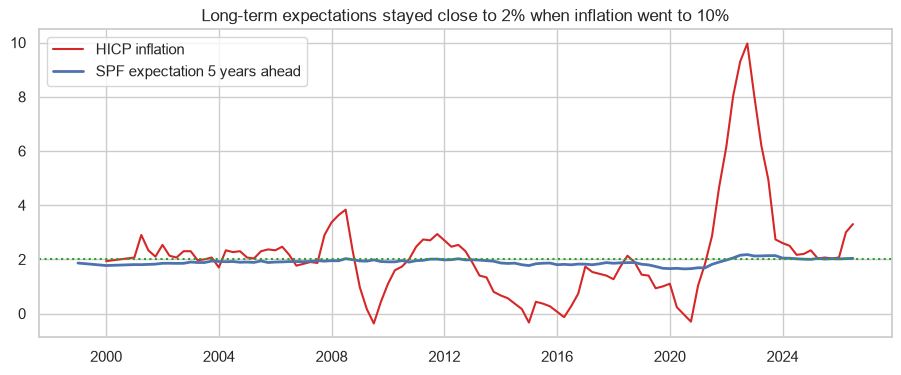

In [5]:
lt = spf[spf["target"] == "LT"].copy()
lt["q"] = pd.PeriodIndex(lt["survey"].str.replace("-", ""), freq="Q")
lt = lt.set_index("q")["forecast"]
actual = hicp["Euro area"].groupby(hicp.index.asfreq("Q")).mean()
a = pd.DataFrame({"lt": lt, "infl": actual}).dropna()
a["d_lt"], a["d_infl"] = a["lt"].diff(), a["infl"].diff()
a = a.dropna()
for nombre, sub in [("2001-2019", a.loc[:"2019Q4"]), ("2020-today", a.loc["2020Q1":])]:
    m = sm.OLS(sub["d_lt"], sm.add_constant(sub["d_infl"])).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    print(nombre, "| beta:", round(m.params["d_infl"], 4), "| t:", round(m.tvalues["d_infl"], 2))
print("Long-term expectation in 2022-2023, min and max:", round(lt.loc["2022Q1":"2023Q4"].min(), 2), round(lt.loc["2022Q1":"2023Q4"].max(), 2))

plt.figure(figsize=(11, 4))
plt.plot(a.index.to_timestamp(), a["infl"], color="tab:red", label="HICP inflation")
plt.plot(lt.index.to_timestamp(), lt, lw=2, label="SPF expectation 5 years ahead")
plt.axhline(2, color="tab:green", ls=":")
plt.title("Long-term expectations stayed close to 2% when inflation went to 10%")
plt.legend()
plt.savefig("figures/anchoring.png", bbox_inches="tight")
plt.show()

## Part 4. France vs the euro area

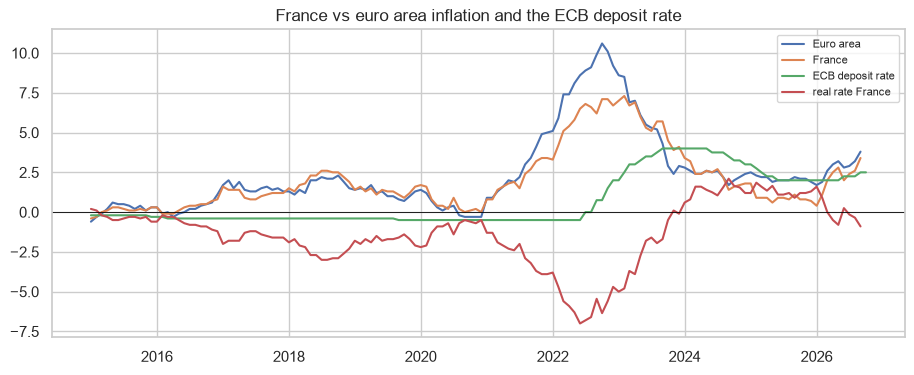

Latest: 2026-09 | EA: 3.8 | FR: 3.4 | deposit rate: 2.5
France - EA, last 12 months: -0.81 | 2015-2019: 0.01
Real rate France: -0.9


In [6]:
fr = pd.DataFrame({"Euro area": hicp["Euro area"], "France": hicp["France"], "ECB deposit rate": dfr}).loc["2015-01":]
fr["real rate France"] = fr["ECB deposit rate"] - fr["France"]
plt.figure(figsize=(11, 4))
for c in fr.columns:
    plt.plot(fr.index.to_timestamp(), fr[c], label=c)
plt.axhline(0, color="black", lw=0.6)
plt.title("France vs euro area inflation and the ECB deposit rate")
plt.legend(fontsize=8)
plt.savefig("figures/france_vs_ea.png", bbox_inches="tight")
plt.show()
gap = (fr["France"] - fr["Euro area"]).dropna()
print("Latest:", fr["Euro area"].dropna().index[-1], "| EA:", fr["Euro area"].dropna().iloc[-1], "| FR:", fr["France"].dropna().iloc[-1], "| deposit rate:", dfr.iloc[-1])
print("France - EA, last 12 months:", round(gap.iloc[-12:].mean(), 2), "| 2015-2019:", round(gap.loc["2015":"2019"].mean(), 2))
print("Real rate France:", round(fr["real rate France"].dropna().iloc[-1], 2))

## Conclusions

- Professional forecasts are very good for the current year but the error grows fast with the horizon, and they underestimate inflation on average. The 2021-2023 shock was the biggest miss in the history of the survey.
- Long-term expectations stayed between 2.0% and 2.2% when inflation reached 10%, so they stayed anchored. But since 2020 they react a little more to current inflation than before.
- In 2026 inflation is going up again (3.8% in the euro area and 3.4% in France in September) and the deposit rate is 2.5%, so the real rate in France is negative again.